# if 분기와 모델 선택 비교

**이 노트북에서 할 일**

1. 질문 낱말을 보고 우리 규칙이 도구를 고르는 그래프를 만들어, 01절 그래프와 나란히 둡니다.
2. 같은 질문 셋을 두 그래프에 보내, 모델 요청 수·실행 흔적·도구 인자·입력 토큰을 견줍니다.
3. 규칙에 없는 낱말로 같은 뜻을 묻는 질문으로 바꿔, 두 그래프가 어떻게 갈리는지 봅니다.

**준비물** — 프로젝트 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
모델은 `gpt-5.4-mini`이고, 교재 출력에서 모델 요청은 모두 12번입니다.
8절에서 3번, 9절에서 6번, 11절에서 3번을 보냈습니다.
모델이 도구를 몇 번 부르느냐에 따라 요청 수가 달라질 수 있습니다.
요금표로 어림한 예상 비용은 모두 합쳐 0.01달러 아래이고, 청구 금액이 아닙니다.

도구는 노트북 안 규정 딕셔너리를 읽기만 하고, 읽는 파일과 새로 쓰는 파일은 없습니다.
앞에서 배운 함수 셋은 도구 파일 `graph_tools.py`에서 가져옵니다.
교재 출력을 만든 실행에서는 노트북 전체가 15초 안에 끝났습니다.
이 절은 두 그래프의 걸린 시간을 재어 견주지 않습니다.

**기준 버전** — 첫 셀에서 패키지 다섯을 설치합니다.
판은 langgraph 1.2.11, langchain 1.4.0, langchain-core 1.6.2입니다.
langchain-openai 1.6.0과 python-dotenv 1.2.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 3~7절을 읽습니다.
두 그래프가 함께 쓰는 부품을 만들고, 규칙 갈래 그래프와 모델 선택 그래프를 조립하는 자리입니다.
8~11절은 질문을 보내 두 그래프를 견주는 자리이고, 실습 시간에 실행합니다.

실습 폴더 `labs/part5/ch20-tool-node`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![칸 둘이 나란히 있는 그림으로 왼쪽 (가) 규칙 갈래 그래프 칸에서는 회색 가상 시작점 START에서 점선 두 갈래가 나갑니다. 주제어 있음 갈래는 파란 상자 요청 노드 request 규칙이 요청을 만듦으로, 주제어 없음 갈래는 보라 상자 답 노드 answer 도구를 모르는 모델로 갑니다. 요청 노드에서 회색 상자 도구 실행 노드 tools, 답 노드, 회색 가상 끝점 END로 실선이 차례로 이어집니다. 오른쪽 (나) 모델 선택 그래프 01절 칸에서는 시작점에서 보라 상자 모델 노드 model 도구를 아는 모델로 가고, 요청 있음 점선은 회색 도구 실행 노드로, 요청 없음 점선은 가상 끝점으로 갑니다. 도구 실행 노드에서 되돌아가는 엣지 실선이 모델 노드로 올라가는 그림](attachment:04-1-도구를-고르는-두-그래프.png)

왼쪽 칸이 규칙 갈래 그래프, 오른쪽 칸이 01절과 같은 모델 선택 그래프입니다.
왼쪽 시작점의 점선 두 갈래는 조건 함수 `pick_by_rule`이, 오른쪽 모델 노드의 점선 두 갈래는 도구 조건 함수가 고릅니다.
두 조건 함수는 노드가 아니라서 상자로 그리지 않았습니다.
파란 상자는 우리 코드가 요청을 만드는 노드, 보라 상자는 모델에 요청을 보내는 노드, 회색은 LangGraph가 준 것입니다.
왼쪽에는 되돌아가는 엣지가 없어, 도구 쪽은 많아야 한 번 다녀옵니다.
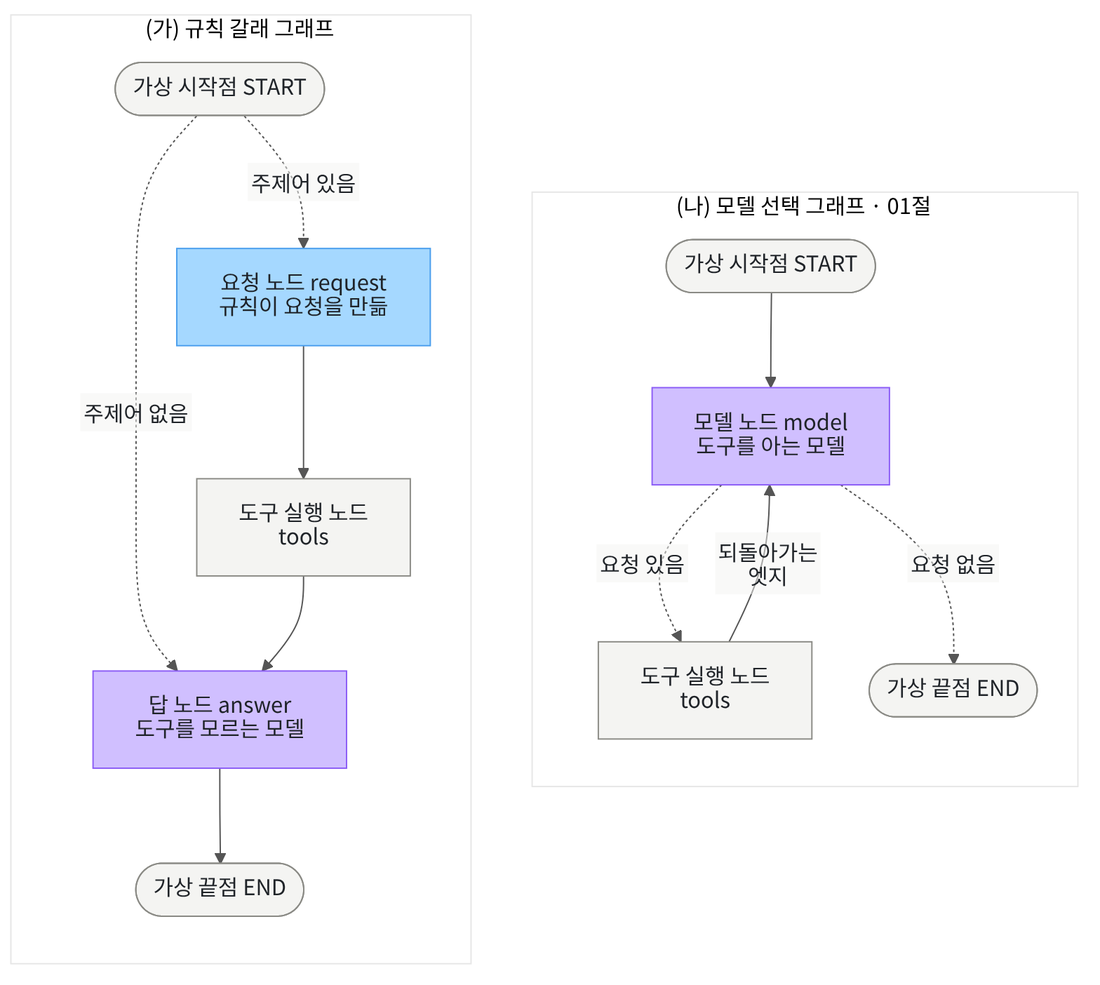

## 1. 준비

이 절은 도구를 고르는 두 방법을 같은 질문으로 견줍니다.
하나는 우리 코드의 `if`가 질문 낱말을 보고 고르는 방법이고, 다른 하나는 01절처럼 모델이 고르는 방법입니다.
제목에 적은 두 방법이 이 둘이고, 코드가 고르는 쪽을 이 절에서는 규칙 갈래라고 부릅니다.

첫 셀은 패키지 다섯 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langgraph==1.2.11" "langchain==1.4.0" "langchain-core==1.6.2" "langchain-openai==1.6.0" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langgraph:", version("langgraph"))
print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langgraph: 1.2.11
langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `langgraph: 1.2.11`·`langchain: 1.4.0`·`langchain-core: 1.6.2`가 보입니다.
출력 줄 `langchain-openai: 1.6.0`과 `python-dotenv: 1.2.3`도 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-24에 이 판으로 실행한 결과입니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
그래프와 메시지 이름은 01절과 같고, 새로 가져오는 라이브러리 이름은 없습니다.
도구 파일에서는 01절에서 쓴 `show_messages`와, 이 절에서 더한 함수 둘을 가져옵니다.

In [2]:
# 01절과 같은 그래프 이름에, 도구 파일의 함수 셋을 가져옵니다
import operator
from typing import Annotated
from typing_extensions import TypedDict

from langchain.chat_models import init_chat_model
from langchain.messages import AIMessage, AnyMessage, HumanMessage
from langchain.tools import tool
from langgraph.graph import END, START, StateGraph
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition

from graph_tools import estimate_cost, show_messages, sum_usage

print("도구 파일에서 새로 가져온 함수:", "estimate_cost", "sum_usage")

도구 파일에서 새로 가져온 함수: estimate_cost sum_usage


**결과 읽기** — 출력 줄 `도구 파일에서 새로 가져온 함수: estimate_cost sum_usage`가 보입니다.

앞에서 배운 함수는 `graph_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다. 커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.

이 절에서 도구 파일에 함수 둘을 더했습니다.
함수 `sum_usage`는 Ch 19 05절, 함수 `estimate_cost`는 Ch 6 06절에서 배웠습니다.
두 함수 모두 Ch 19 도구 파일 `order_tools.py`의 본문을 글자 그대로 옮겼습니다.

## 2. 키와 모델 준비

모델은 01절과 같은 `gpt-5.4-mini`이고, 과정의 같은 설정으로 부릅니다.
이 절은 이 모델을 두 가지로 씁니다.
규칙 갈래 그래프에서는 도구를 알려 주지 않은 채 답만 받습니다.
모델 선택 그래프에서는 01절처럼 도구를 알려 준 모델이 도구를 고릅니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어도, 모델이 도구 호출 요청을 보낼지가 매번 같다고 보장하지는 않습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-24에 이 모델로 실행한 결과입니다.

## 3. 규정 자료와 도구

이 절도 교육센터 자료실 규정 셋을 소재로 씁니다.
다음 셀은 01절과 글자까지 같은 셀로, 주제어를 키로 한 규정 딕셔너리를 만듭니다.

In [5]:
# 교육센터 자료실 규정 셋을, 주제어를 키로 한 딕셔너리에 담습니다(도구가 읽기만 하는 자료)
POLICIES = {
    "대출": "일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.",
    "운영": "평일은 09:00~20:00, 토요일은 10:00~17:00에 운영합니다.",
    "연체": "연체한 일수만큼 새 대출이 제한됩니다.",
}
topics = list(POLICIES.keys())
print("규정 주제어:", topics)

규정 주제어: ['대출', '운영', '연체']


**결과 읽기** — 출력 줄 `규정 주제어: ['대출', '운영', '연체']`로 키 셋을 확인합니다.
이 세 주제어는 뒤에서 우리 규칙이 질문 속에서 찾을 낱말이기도 합니다.

다음 셀은 01절 도구와 코드가 같은 도구를 만듭니다.
오류 줄 위 주석 한 줄만 03절 판처럼 「02절에서 본 ValueError」로 적었습니다.

In [6]:
# 주제어 하나로 규정 글 하나를 찾는 도구를 만듭니다(맨 @tool 줄 — Ch 19 01절)
@tool
def lookup_policy(topic: str):
    """교육센터 자료실 규정 하나를 주제어로 찾습니다. topic에는 대출, 운영, 연체 가운데 하나를 넣습니다."""
    # 딕셔너리에 없는 주제어면 오류를 냅니다(02절에서 본 ValueError입니다)
    if topic not in POLICIES:
        raise ValueError("지원하지 않는 주제: " + topic)
    return POLICIES[topic]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
도구 설명(독스트링)은 도구를 알려 준 요청에만 실립니다.

다음 셀은 01절과 글자까지 같은 셀로, 도구 목록을 모델에게 알려 준 `bound_model`을 만듭니다.
이 모델은 모델 선택 그래프에서만 씁니다.

In [7]:
# 도구 목록을 모델에게 알려 줍니다(Ch 19 04절 bind_tools, 요청은 아직 보내지 않음)
tools = [lookup_policy]
# 한 응답에 도구 호출 요청을 하나까지만 받게 합니다(Ch 19 06절과 같은 값)
bound_model = model.bind_tools(tools, parallel_tool_calls=False)
print("실어 보낼 명세 수:", len(bound_model.kwargs["tools"]))
print("여럿 담기:", bound_model.kwargs["parallel_tool_calls"])

실어 보낼 명세 수: 1
여럿 담기: False


**결과 읽기** — 출력 줄 `실어 보낼 명세 수: 1`과 `여럿 담기: False`는 01절과 같습니다.
규칙 갈래 그래프의 답 노드는 이 모델이 아니라 2절에서 만든 `model`을 씁니다.
그래서 규칙 갈래 쪽 요청에는 도구 명세가 실리지 않습니다.

## 4. 두 그래프가 함께 쓰는 부품

두 그래프는 상태 형식과 도구 실행 노드를 함께 씁니다.
상태 형식은 01절과 같은 `AgentState`입니다.
메시지 칸에는 메시지 리듀서, 실행 흔적 칸에는 이어 붙이기 규칙을 적습니다.

In [8]:
# 메시지 칸과 실행 흔적 칸에 각각 규칙을 적은 상태 형식을 만듭니다(Ch 13 04절 모양)
class AgentState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]
    trace: Annotated[list[str], operator.add]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
01절 셀과 글자까지 같고, 칸 구성이 같아 새 이름을 붙이지 않았습니다.

다음 셀은 01절 5절과 글자까지 같은 셀로 도구 실행 노드를 만듭니다.
이 노드 하나를 두 그래프에 함께 등록합니다.

In [9]:
# 도구 목록으로 도구 실행 노드를 만듭니다(아직 그래프에 넣지 않음)
tool_node = ToolNode(tools)
print("만든 것의 종류:", type(tool_node).__name__)
# 속성 tools_by_name은 Ch 19 05절의 도구 찾기 표와 같은 모양입니다
table_keys = list(tool_node.tools_by_name.keys())
print("안에 든 도구 찾기 표의 키:", table_keys)

만든 것의 종류: ToolNode
안에 든 도구 찾기 표의 키: ['lookup_policy']


**결과 읽기** — 출력 줄 `만든 것의 종류: ToolNode`와 `안에 든 도구 찾기 표의 키: ['lookup_policy']`입니다.
두 그래프 모두 도구 실행은 이 노드가 맡습니다.
그래서 도구를 실행하는 쪽은 같고, 도구 호출 요청을 누가 만드느냐만 다릅니다.

## 5. 우리 규칙이 고르는 갈래

규칙 갈래 그래프에서는 우리 코드가 도구를 고릅니다.
규칙은 이렇게 정합니다. 질문에 규정 주제어가 글자 그대로 있으면, 그 주제어로 규정을 찾습니다.
주제어가 여럿이면 딕셔너리 키 차례대로 먼저 맞은 하나만 찾고, 하나도 없으면 찾지 않습니다.

다음 셀은 이 규칙을 여러 줄 `if`로 적은 함수입니다.
글 `A in B`는 글 A가 글 B 안에 들어 있으면 `True`입니다.
맞은 `if`에서 바로 주제어를 내놓으므로, 그 뒤의 `if`는 보지 않습니다.

In [10]:
# 질문에 규정 주제어가 글자 그대로 있는지 차례로 보고, 먼저 맞은 주제어 하나를 내놓습니다(없으면 빈 글)
def keyword_topic(question):
    if "대출" in question:
        return "대출"
    if "운영" in question:
        return "운영"
    if "연체" in question:
        return "연체"
    return ""

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `keyword_topic`은 주제어 하나나 빈 글을 내놓습니다.
빈 글은 03절에서처럼 「찾을 주제어가 없음」을 뜻합니다.

다음 셀은 이 절에서 쓸 질문 셋을 정하고, 모델 없이 규칙 함수에 넣어 봅니다.
대출 질문은 01절 대출 질문의 「빌릴」을 규정 주제어가 든 「대출할」로 바꾼 글입니다.
인사 질문과 운영·연체 질문은 01절 글 그대로입니다.

In [11]:
# 이 절의 질문 셋을 정하고, 모델 없이 규칙 함수에 하나씩 넣어 봅니다
loan_question = "자료실에서 일반 도서를 며칠 대출할 수 있나요?"
greet_question = "안녕하세요. 한 문장으로 인사해 주세요."
two_question = "자료실 운영 시간과 연체 규정을 함께 알려 주세요."
rule_picks = [keyword_topic(loan_question), keyword_topic(greet_question), keyword_topic(two_question)]
print("규칙 함수가 내놓은 값(대출·인사·운영·연체 질문 차례):", rule_picks)
# 모델 없이 코드가 정하는 값이라 매번 같아야 합니다
assert rule_picks == ["대출", "", "운영"], "규칙 함수는 적어 둔 차례대로 주제어를 골라야 합니다"

규칙 함수가 내놓은 값(대출·인사·운영·연체 질문 차례): ['대출', '', '운영']


**결과 읽기** — 출력 줄 끝의 목록 `['대출', '', '운영']`이 세 질문에 대한 규칙 함수의 값입니다.
대출 질문은 `대출`이고, 인사 질문은 빈 글입니다.
운영·연체 질문에는 주제어가 둘 있지만, 먼저 맞은 `운영` 하나만 나왔습니다.
모델 없이 코드가 정하는 값이라, 셀 끝 `assert`로 확인했습니다.

다음은 조건부 엣지에 넣을 조건 함수입니다.
Ch 13 03절 조건 함수처럼 상태를 받아 이름표를 내놓습니다.
첫 메시지인 질문에 규칙을 대어, 주제어가 없으면 `"answer"`, 있으면 `"request"`를 내놓습니다.
Ch 18 02절 라우팅에서는 모델이 쓴 문의 종류를 보고 코드가 갈래를 골랐습니다.
이 조건 함수는 모델에게 묻지 않고, 질문에 든 낱말만 봅니다.

In [12]:
# 질문을 규칙 함수에 넣어, 요청 노드와 답 노드 가운데 갈 곳의 이름표를 고릅니다(모델을 부르지 않음)
def pick_by_rule(state):
    question = state["messages"][0].content
    if keyword_topic(question) == "":
        return "answer"
    return "request"

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이 함수도 노드로 등록하지 않고 조건부 엣지에 넣습니다.
01절 도구 조건 함수가 모델의 응답을 보았다면, 이 함수는 질문을 봅니다.

다음 셀은 대출 질문과 인사 질문으로 첫 상태를 만들어, 조건 함수를 그래프 없이 불러 봅니다.
두 이름표를 실제로 갈 노드에 잇는 이름표 표도 함께 만듭니다.

In [13]:
# 대출·인사 질문으로 첫 상태를 만들고, 조건 함수를 그래프 없이 직접 불러 봅니다(Ch 13 03절)
loan_state = {"messages": [HumanMessage(content=loan_question)], "trace": []}
greet_state = {"messages": [HumanMessage(content=greet_question)], "trace": []}
print("대출 질문의 이름표:", pick_by_rule(loan_state))
print("인사 질문의 이름표:", pick_by_rule(greet_state))
# 이름표 둘을 같은 이름의 노드에 잇습니다(끝점으로 가는 이름표는 없음)
rule_path_map = {"request": "request", "answer": "answer"}
print("규칙 갈래의 이름표 표:", rule_path_map)

대출 질문의 이름표: request
인사 질문의 이름표: answer
규칙 갈래의 이름표 표: {'request': 'request', 'answer': 'answer'}


**결과 읽기** — 출력 줄 `대출 질문의 이름표: request`와 `인사 질문의 이름표: answer`입니다.
라벨 `규칙 갈래의 이름표 표:` 뒤 딕셔너리는 두 이름표를 같은 이름의 노드에 잇습니다.
이 표에는 끝점으로 가는 이름표가 없습니다.
어느 갈래로 가든, 끝으로 가는 일은 답 노드 뒤의 엣지가 맡습니다.

## 6. 규칙 갈래 그래프 조립

요청 노드는 규칙이 고른 주제어로 도구 호출 요청을 손으로 만듭니다.
01절 5절에서 손으로 만든 응답과 같은 모양이고, 칸 넷(`name`·`args`·`id`·`type`)을 적습니다.
모델을 부르지 않으므로 이 노드에서는 모델 요청이 나가지 않습니다.
만든 요청은 도구 실행 노드가 받아 실행합니다.

In [14]:
# 규칙이 고른 주제어로 도구 호출 요청을 손으로 만들어 메시지 칸에 더합니다(01절 5절 모양, 모델 요청 없음)
def make_rule_request(state):
    question = state["messages"][0].content
    topic = keyword_topic(question)
    rule_call = {"name": "lookup_policy", "args": {"topic": topic}, "id": "rule_call_1", "type": "tool_call"}
    request = AIMessage(content="", tool_calls=[rule_call])
    return {"messages": [request], "trace": ["request"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
요청의 호출 ID는 글 `rule_call_1`로 정해 두었습니다.
도구 실행 노드가 이 값을 도구 메시지에 옮겨 적습니다.

다음 셀은 답 노드입니다.
01절 모델 노드와 모양이 같지만, 도구를 알려 주지 않은 `model`을 부릅니다.
고르는 일은 규칙이 이미 했으므로, 모델은 받은 메시지를 읽고 답만 씁니다.

In [15]:
# 도구를 알려 주지 않은 모델에 메시지 칸 전체를 보내고, 답 하나와 노드 이름만 냅니다
def call_answer(state):
    response = model.invoke(state["messages"])
    return {"messages": [response], "trace": ["answer"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이 노드를 지날 때마다 모델 요청이 한 번 나가고, 실행 흔적 칸에 `answer`가 붙습니다.
규칙 갈래 그래프에서 모델 요청이 나가는 곳은 이 노드뿐입니다.

다음 셀은 노드 셋을 등록하고 엣지를 적어 컴파일합니다.
이번에는 조건부 엣지를 시작점 `START` 뒤에 둡니다.
그래프가 시작하자마자 조건 함수가 질문을 보고 첫 노드를 고르는 모양입니다.

In [16]:
# 규칙 갈래 그래프를 조립합니다(조건부 엣지를 시작점 START 뒤에 둡니다)
rule_builder = StateGraph(AgentState)
rule_builder.add_node("request", make_rule_request)
rule_builder.add_node("tools", tool_node)
rule_builder.add_node("answer", call_answer)
rule_builder.add_conditional_edges(START, pick_by_rule, rule_path_map)
rule_builder.add_edge("request", "tools")
rule_builder.add_edge("tools", "answer")
rule_builder.add_edge("answer", END)
rule_graph = rule_builder.compile()

**결과 읽기** — 이 셀은 조립만 하고 출력이 없습니다.
요청 노드 다음은 도구 실행 노드, 그다음은 답 노드로 가는 고정 엣지입니다.
규칙 갈래 그래프에는 되돌아가는 엣지가 없어서, 도구 쪽은 많아야 한 번 다녀옵니다.

다음 셀은 이 그래프가 스스로 그린 구조 문자열을 받아 옵니다.

In [17]:
# 규칙 갈래 그래프가 스스로 그린 구조 문자열을 받아 옵니다(Ch 13 01절)
rule_structure = rule_graph.get_graph().draw_mermaid()
print("등록한 노드:", list(rule_builder.nodes))
print("그래프가 그린 구조:")
print(rule_structure)

등록한 노드: ['request', 'tools', 'answer']
그래프가 그린 구조:
---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	request(request)
	tools(tools)
	answer(answer)
	__end__([<p>__end__</p>]):::last
	__start__ -.-> answer;
	__start__ -.-> request;
	request --> tools;
	tools --> answer;
	answer --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



**결과 읽기** — 출력 줄 `등록한 노드: ['request', 'tools', 'answer']`입니다.
라벨 줄 `그래프가 그린 구조:` 아래에서 화살표 줄 다섯을 봅니다.
줄 `__start__ -.-> answer`와 `__start__ -.-> request`는 시작점 뒤 조건부 엣지의 두 갈래라 점선입니다.
나머지 세 줄은 실선이고, 뒤 노드에서 앞 노드로 되돌아가는 줄은 없습니다.

## 7. 모델 선택 그래프

모델 선택 그래프는 01절 그래프를 그대로 다시 조립합니다.
다음 셀은 01절 모델 노드와 글자까지 같은 셀입니다.
모델 노드는 도구를 알려 준 `bound_model`에 메시지 칸 전체를 보냅니다.

In [18]:
# 메시지 칸 전체를 도구를 알려 준 모델에 보내고, 응답 하나와 노드 이름만 냅니다
def call_model(state):
    response = bound_model.invoke(state["messages"])
    return {"messages": [response], "trace": ["model"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이 노드를 지날 때마다 모델 요청이 한 번 나가고, 실행 흔적 칸에 `model`이 붙습니다.
도구를 부를지와 어떤 인자를 넣을지는 이 요청의 응답이 정합니다.

다음 셀은 01절 5·6절과 같은 이름표 표와 엣지로 그래프를 조립합니다.
도구 실행 노드는 4절에서 만든 `tool_node`를 다시 씁니다.

In [19]:
# 01절 5·6절과 같은 이름표 표와 엣지로 모델 선택 그래프를 조립합니다
path_map = {"tools": "tools", END: END}
model_builder = StateGraph(AgentState)
model_builder.add_node("model", call_model)
model_builder.add_node("tools", tool_node)
model_builder.add_edge(START, "model")
model_builder.add_conditional_edges("model", tools_condition, path_map)
model_builder.add_edge("tools", "model")
model_graph = model_builder.compile()
print("등록한 노드:", list(model_builder.nodes))

등록한 노드: ['model', 'tools']


**결과 읽기** — 출력 줄 `등록한 노드: ['model', 'tools']`입니다.
도구 조건 함수, 이름표 표, 되돌아가는 엣지 `tools → model`은 01절과 같습니다.
두 그래프 모두 같은 도구 실행 노드를 등록했습니다.

## 8. 대출 질문을 두 그래프에

첫 질문은 규정 주제어 「대출」이 든 대출 질문입니다.
5절에서 만든 첫 상태 `loan_state`를 두 그래프에 한 번씩 넣습니다.
실행 전에 예상해 봅니다.
규칙 갈래는 요청 노드·도구 실행 노드·답 노드를 지나고, 모델 요청은 1번일 것입니다.
모델 선택은 01절처럼 모델 노드를 두 번 지나, 모델 요청이 2번일 것입니다.

In [20]:
# 대출 질문을 두 그래프에 한 번씩 보냅니다(모델 요청은 규칙 갈래 1번, 모델 선택 2번 예상)
loan_rule = rule_graph.invoke(loan_state)
loan_model = model_graph.invoke(loan_state)
print("규칙 갈래 | 실행 흔적 칸:", loan_rule["trace"])
print("모델 선택 | 실행 흔적 칸:", loan_model["trace"])

규칙 갈래 | 실행 흔적 칸: ['request', 'answer']
모델 선택 | 실행 흔적 칸: ['model', 'model']


**결과 읽기** — 출력 줄 `규칙 갈래 | 실행 흔적 칸: ['request', 'answer']`입니다.
출력 줄 `모델 선택 | 실행 흔적 칸: ['model', 'model']`입니다.
도구 실행 노드는 01절에서 본 것처럼 흔적 칸을 쓰지 않아, 두 흔적 모두 도구 실행이 보이지 않습니다.
모델 요청은 규칙 갈래가 `answer` 한 번, 모델 선택이 `model` 두 번입니다.

다음 셀은 Ch 19 06절 함수 `show_messages`로 두 메시지 칸을 차례로 출력합니다.

In [21]:
# 두 그래프의 메시지 칸을 차례로 출력합니다(Ch 19 06절 함수 show_messages)
print("규칙 갈래 그래프의 메시지 칸:")
show_messages(loan_rule["messages"])
print("모델 선택 그래프의 메시지 칸:")
show_messages(loan_model["messages"])

규칙 갈래 그래프의 메시지 칸:
HumanMessage
AIMessage | 도구 호출 요청: ['lookup_policy']
ToolMessage | 결과 상태: success | 내용: 일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.
AIMessage | 도구 호출 요청: []
모델 선택 그래프의 메시지 칸:
HumanMessage
AIMessage | 도구 호출 요청: ['lookup_policy']
ToolMessage | 결과 상태: success | 내용: 일반 도서는 1인 5권까지 14일 동안 대출할 수 있습니다.
AIMessage | 도구 호출 요청: []


**결과 읽기** — 라벨 줄 두 개 아래 네 줄씩이, 두 그래프의 메시지 칸입니다.
두 칸 모두 둘째 줄이 `AIMessage | 도구 호출 요청: ['lookup_policy']`입니다.
셋째 줄 도구 메시지도 두 칸 모두 결과 상태 `success`에 대출 규정 글입니다.
메시지 모양만으로는 둘째 줄의 요청을 누가 만들었는지 가를 수 없습니다.

다음 셀은 메시지마다 붙은 사용량을 봅니다.
사용량(`usage_metadata`)은 Ch 6에서 본, 모델 응답에 붙는 토큰 수입니다.

In [22]:
# 두 흐름의 둘째·넷째 메시지에 붙은 사용량을 봅니다(요청 없음, 손으로 만든 요청은 None)
print("규칙 갈래 | 둘째 메시지(요청)의 사용량:", loan_rule["messages"][1].usage_metadata)
print("규칙 갈래 | 넷째 메시지(답)의 입력 토큰:", loan_rule["messages"][3].usage_metadata["input_tokens"])
print("모델 선택 | 둘째 메시지(첫 응답)의 입력 토큰:", loan_model["messages"][1].usage_metadata["input_tokens"])
print("모델 선택 | 넷째 메시지(둘째 응답)의 입력 토큰:", loan_model["messages"][3].usage_metadata["input_tokens"])

규칙 갈래 | 둘째 메시지(요청)의 사용량: None
규칙 갈래 | 넷째 메시지(답)의 입력 토큰: 72
모델 선택 | 둘째 메시지(첫 응답)의 입력 토큰: 164
모델 선택 | 넷째 메시지(둘째 응답)의 입력 토큰: 214


**결과 읽기** — 출력 줄 `규칙 갈래 | 둘째 메시지(요청)의 사용량: None`입니다.
규칙 갈래의 요청은 우리 코드가 만들어, 모델 요청이 아니므로 사용량이 없습니다.
규칙 갈래 답 요청의 입력 토큰은 출력 줄 끝의 `72`입니다.
모델 선택의 첫 요청은 `164`, 둘째 요청은 `214`입니다.

규칙 갈래의 답 요청과 모델 선택의 둘째 요청은 모두 질문·요청·도구 메시지 셋을 보냅니다.
셈으로는 두 요청의 입력 토큰 차이가 142이고, 모델 선택 쪽에만 도구를 알려 주었습니다.
이 차이는 9절 인사 질문에서 한 번 더 봅니다.

## 9. 세 질문 견주기

인사 질문과 운영·연체 질문도 두 그래프에 보내, 세 질문을 한 표로 견줍니다.
먼저 표를 만들 함수 셋을 정의합니다.
도구 파일 함수 `sum_usage`는 `AIMessage`를 모두 모델 응답으로 보고 사용량을 더합니다.
규칙 갈래의 요청도 `AIMessage`라, 그대로 넘기면 사용량 `None`에서 오류가 납니다.
그래서 첫 함수는 사용량이 있는 응답만 골라 새 목록에 담습니다.

In [23]:
# 메시지 목록에서 모델이 쓴 응답만 골라 새 목록으로 내놓습니다(사용량이 None인 손 요청은 뺍니다)
def model_responses(messages):
    responses = []
    for message in messages:
        if type(message).__name__ == "AIMessage":
            if message.usage_metadata is not None:
                responses.append(message)
    return responses

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `model_responses`는 `AIMessage`이면서 사용량이 `None`이 아닌 메시지만 담습니다.
받은 목록은 고치지 않고, 새 목록을 내놓습니다.

다음 셀은 메시지 목록에서 도구 호출 요청의 주제어 인자만 차례로 모으는 함수입니다.
요청을 모델이 만들었든 우리 규칙이 만들었든 함께 모읍니다.

In [24]:
# 메시지 목록의 도구 호출 요청에서 주제어 인자만 차례로 모아 내놓습니다(누가 만든 요청이든)
def called_topics(messages):
    asked_topics = []
    for message in messages:
        if type(message).__name__ == "AIMessage":
            for call in message.tool_calls:
                asked_topics.append(call["args"]["topic"])
    return asked_topics

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `called_topics`는 응답마다 도구 호출 요청의 칸 `args`에서 `topic` 값을 꺼냅니다.
요청이 하나도 없으면 빈 목록을 내놓습니다.

다음 셀은 실행 결과 하나를 견주기 한 줄로 만드는 함수입니다.
모델 요청 수와 입력 토큰은 모델 응답만 골라 `sum_usage`로 셉니다.

In [25]:
# 실행 결과 하나를 견주기 한 줄로 만듭니다(모델 요청 수와 입력 토큰은 모델 응답에서 셉니다)
def compare_row(graph_name, result):
    responses = model_responses(result["messages"])
    usage = sum_usage(responses)
    row = {"그래프": graph_name, "실행 흔적": result["trace"]}
    row["모델 요청 수"] = usage["requests"]
    row["도구 인자"] = called_topics(result["messages"])
    row["입력 토큰"] = usage["input_tokens"]
    return row

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `compare_row`는 칸 다섯을 담은 딕셔너리를 내놓습니다.
칸은 그래프·실행 흔적·모델 요청 수·도구 인자·입력 토큰입니다.

다음 셀은 인사 질문과 운영·연체 질문을 두 그래프에 한 번씩 보냅니다.
실행 전에 예상해 봅니다.
규칙 갈래는 두 질문 모두 모델 요청 1번이고, 인사 질문에서는 도구 쪽에 가지 않을 것입니다.
모델 선택은 01절처럼 인사 질문 1번, 운영·연체 질문 3번일 것입니다.

In [26]:
# 인사·운영·연체 질문을 두 그래프에 한 번씩 보냅니다(모델 요청은 규칙 갈래 2번, 모델 선택 4번 예상)
two_state = {"messages": [HumanMessage(content=two_question)], "trace": []}
greet_rule = rule_graph.invoke(greet_state)
greet_model = model_graph.invoke(greet_state)
two_rule = rule_graph.invoke(two_state)
two_model = model_graph.invoke(two_state)
print("인사 질문 | 규칙 갈래:", greet_rule["trace"], "| 모델 선택:", greet_model["trace"])
print("운영·연체 질문 | 규칙 갈래:", two_rule["trace"], "| 모델 선택:", two_model["trace"])

인사 질문 | 규칙 갈래: ['answer'] | 모델 선택: ['model']
운영·연체 질문 | 규칙 갈래: ['request', 'answer'] | 모델 선택: ['model', 'model', 'model']


**결과 읽기** — 출력 줄 `인사 질문 | 규칙 갈래: ['answer'] | 모델 선택: ['model']`입니다.
인사 질문은 두 그래프 모두 도구 쪽에 가지 않았습니다.
출력 줄 `운영·연체 질문 | 규칙 갈래: ['request', 'answer'] | 모델 선택: ['model', 'model', 'model']`입니다.
운영·연체 질문에서 모델 선택 그래프는 모델 노드를 세 번 지났습니다.

다음 셀은 세 질문의 결과를 견주기 줄로 만들어 한 줄씩 출력합니다.

In [27]:
# 세 질문의 두 그래프 결과를 견주기 줄로 만들어, 라벨 줄 아래에 한 줄씩 출력합니다
main_runs = [["대출", loan_rule, loan_model], ["인사", greet_rule, greet_model], ["운영·연체", two_rule, two_model]]
print("질문 | 그래프 | 실행 흔적 | 모델 요청 수 | 도구 인자 | 입력 토큰")
for run in main_runs:
    rule_row = compare_row("규칙 갈래", run[1])
    model_row = compare_row("모델 선택", run[2])
    for row in [rule_row, model_row]:
        print(run[0], "|", row["그래프"], "|", row["실행 흔적"], "|", row["모델 요청 수"], "|", row["도구 인자"], "|", row["입력 토큰"])

질문 | 그래프 | 실행 흔적 | 모델 요청 수 | 도구 인자 | 입력 토큰
대출 | 규칙 갈래 | ['request', 'answer'] | 1 | ['대출'] | 72
대출 | 모델 선택 | ['model', 'model'] | 2 | ['대출'] | 378
인사 | 규칙 갈래 | ['answer'] | 1 | [] | 18
인사 | 모델 선택 | ['model'] | 1 | [] | 160
운영·연체 | 규칙 갈래 | ['request', 'answer'] | 1 | ['운영'] | 75
운영·연체 | 모델 선택 | ['model', 'model', 'model'] | 3 | ['운영', '연체'] | 638


**결과 읽기** — 라벨 줄 아래 여섯 줄이 질문마다 규칙 갈래와 모델 선택 한 줄씩입니다.
대출 질문은 `대출 | 규칙 갈래 | ['request', 'answer'] | 1 | ['대출'] | 72`와 `대출 | 모델 선택 | ['model', 'model'] | 2 | ['대출'] | 378`입니다.
인사 질문은 `인사 | 규칙 갈래 | ['answer'] | 1 | [] | 18`과 `인사 | 모델 선택 | ['model'] | 1 | [] | 160`입니다.
운영·연체 질문은 `1 | ['운영'] | 75`와 `3 | ['운영', '연체'] | 638`입니다.
규칙 갈래는 세 질문 모두 모델 요청이 1번이었고, 운영·연체 질문에서 운영 규정 하나만 찾았습니다.

인사 질문은 두 그래프가 같은 메시지 하나를 보냈고, 입력 토큰 차이는 142입니다.
두 요청은 도구를 알려 주었는지만 다르므로, 이 차이는 도구 명세가 실린 몫입니다.
8절 대출 질문에서 본 차이 142와 같습니다.
모델 선택 그래프는 모델 요청마다 이만큼을 더 보냅니다.

## 10. 요청 수와 예상 비용

Ch 17 05절 자율성 진단표는 두 흐름의 호출 수·비용·결과 편차를 견주라고 적어 두었습니다.
이 절에서 호출 수는 모델 요청 수로, 비용은 예상 비용으로 셉니다.
결과 편차는 같은 질문을 여러 번 보내야 셀 수 있어, 노트북 밖에서 세어 본문 6에 적었습니다.
다음 셀은 세 질문의 모델 응답을 그래프마다 모아 `sum_usage`로 더합니다.

In [28]:
# 세 질문에서 그래프마다 모델 응답을 모두 모아 요청 수와 토큰을 더합니다(Ch 19 05절 함수 sum_usage)
rule_responses = []
model_side_responses = []
for run in main_runs:
    rule_responses = rule_responses + model_responses(run[1]["messages"])
    model_side_responses = model_side_responses + model_responses(run[2]["messages"])
rule_usage = sum_usage(rule_responses)
model_usage = sum_usage(model_side_responses)
print("규칙 갈래 그래프:", rule_usage)
print("모델 선택 그래프:", model_usage)

규칙 갈래 그래프: {'requests': 3, 'input_tokens': 165, 'output_tokens': 135}
모델 선택 그래프: {'requests': 6, 'input_tokens': 1176, 'output_tokens': 151}


**결과 읽기** — 출력 줄은 `규칙 갈래 그래프: {'requests': 3, 'input_tokens': 165`로 시작합니다.
다음 출력 줄은 `모델 선택 그래프: {'requests': 6, 'input_tokens': 1176`로 시작합니다.
모델 요청은 3번과 6번, 입력 토큰은 165와 1176입니다.
모델 선택 그래프는 도구를 고르는 요청이 더 있고, 요청마다 도구 명세가 실렸습니다.

칸 `output_tokens`는 답 글 길이에 따라 실행마다 달라질 수 있습니다.
이번 실행에서는 출력 토큰이 규칙 갈래 135, 모델 선택 151이었습니다.
새 커널로 한 번 더 실행했을 때는 규칙 갈래 쪽 값이 달랐습니다.

다음 셀은 Ch 6 06절 요금표로 두 그래프의 예상 비용을 셉니다.
요금은 Ch 19 06절과 같은 2026-09-17 값이고, 이름 있는 변수로 둡니다.
예상 비용은 요금표로 어림한 값이고, 청구 금액이 아닙니다.

In [29]:
# 2026-09-17 요금표(100만 토큰당 달러)로 두 그래프의 예상 비용을 셉니다(Ch 6 06절 함수 estimate_cost)
pricing_date = "2026-09-17"
input_rate = 0.75
cached_input_rate = 0.075
output_rate = 4.50
rule_cost = estimate_cost(rule_usage, input_rate, cached_input_rate, output_rate)
model_cost = estimate_cost(model_usage, input_rate, cached_input_rate, output_rate)
print("요금 확인 날짜:", pricing_date)
print("규칙 갈래 예상 비용(달러):", round(rule_cost, 6))
print("모델 선택 예상 비용(달러):", round(model_cost, 6))

요금 확인 날짜: 2026-09-17
규칙 갈래 예상 비용(달러): 0.000731
모델 선택 예상 비용(달러): 0.001561


**결과 읽기** — 출력 줄 `요금 확인 날짜: 2026-09-17`은 요금표를 확인한 날짜입니다.
라벨 `규칙 갈래 예상 비용(달러):`과 `모델 선택 예상 비용(달러):` 뒤가 두 그래프의 예상 비용입니다.
예상 비용에는 출력 토큰 몫도 들어 있어, 실행마다 조금씩 달라질 수 있습니다.

이번 실행에서는 규칙 갈래 0.000731달러, 모델 선택 0.001561달러였습니다.
새 커널로 한 번 더 실행했을 때는 규칙 갈래 쪽 값이 달라, 예상 비용 합은 결론에 쓰지 않습니다.

출력 토큰은 답 글 길이에 따라 달라지지만, 입력 토큰은 같은 요청이면 같았습니다.
그래서 다음 셀은 출력 요금 자리에 0을 넣어, 예상 비용 가운데 입력 토큰 몫만 셉니다.
함수는 그대로 두고, 0을 담은 변수를 인자 `output_rate` 자리에 넘깁니다.

In [30]:
# 출력 요금 자리에 0을 넣어, 예상 비용 가운데 입력 토큰 몫만 셉니다
no_output_rate = 0
rule_input_cost = estimate_cost(rule_usage, input_rate, cached_input_rate, no_output_rate)
model_input_cost = estimate_cost(model_usage, input_rate, cached_input_rate, no_output_rate)
print("규칙 갈래 입력 몫(달러):", round(rule_input_cost, 6))
print("모델 선택 입력 몫(달러):", round(model_input_cost, 6))

규칙 갈래 입력 몫(달러): 0.000124
모델 선택 입력 몫(달러): 0.000882


**결과 읽기** — 출력 줄 `규칙 갈래 입력 몫(달러): 0.000124`와 `모델 선택 입력 몫(달러): 0.000882`입니다.
세 질문에서 모델 선택 그래프의 입력 몫이 규칙 갈래보다 컸습니다.
모델 요청이 두 배였고, 요청마다 도구 명세가 실렸습니다.
운영·연체 질문에서 규칙 갈래가 규정 하나만 찾은 차이도 이 값에 들어 있습니다.

## 11. 값 바꿔 보기 · 규칙에 없는 낱말로 묻기

바꿀 값은 질문 하나입니다.
대출 질문의 「대출할」만 「빌릴」로 바꿔, 뜻은 같고 규정 주제어는 없는 질문을 만듭니다.
이 글은 01절 대출 질문 그대로입니다.
실행 전에 예상해 봅니다.
규칙 갈래는 주제어를 찾지 못해 도구 쪽에 가지 않고, 모델 선택은 대출 규정을 찾을 것입니다.

In [31]:
# 바꿀 값: 대출 질문의 「대출할」만 「빌릴」로 바꿔 두 그래프에 한 번씩 보냅니다(모델 요청 3번 예상)
borrow_question = "자료실에서 일반 도서를 며칠 빌릴 수 있나요?"
borrow_state = {"messages": [HumanMessage(content=borrow_question)], "trace": []}
borrow_rule = rule_graph.invoke(borrow_state)
borrow_model = model_graph.invoke(borrow_state)
print("규칙 함수가 내놓은 값이 빈 글인가:", keyword_topic(borrow_question) == "")
print("그래프 | 실행 흔적 | 모델 요청 수 | 도구 인자 | 입력 토큰")
for row in [compare_row("규칙 갈래", borrow_rule), compare_row("모델 선택", borrow_model)]:
    print(row["그래프"], "|", row["실행 흔적"], "|", row["모델 요청 수"], "|", row["도구 인자"], "|", row["입력 토큰"])

규칙 함수가 내놓은 값이 빈 글인가: True
그래프 | 실행 흔적 | 모델 요청 수 | 도구 인자 | 입력 토큰
규칙 갈래 | ['answer'] | 1 | [] | 22
모델 선택 | ['model', 'model'] | 2 | ['대출'] | 378


**결과 읽기** — 출력 줄 `규칙 함수가 내놓은 값이 빈 글인가: True`입니다.
라벨 줄 아래 첫 줄은 `규칙 갈래 | ['answer'] | 1 | [] | 22`입니다.
규칙 갈래는 조건 함수가 이름표 `answer`를 골라, 도구 쪽에 가지 않았습니다.
둘째 줄은 `모델 선택 | ['model', 'model'] | 2 | ['대출'] | 378`입니다.
모델은 「빌릴」로 물어도 주제어 `대출`을 골라 규정을 찾았습니다.

모델 쪽 결과는 모델이 정한 값이라 실행마다 달라질 수 있습니다.
노트북 밖에서 이 질문을 다섯 번 보냈을 때는 다섯 번 모두 이 줄과 같았습니다.

다음 셀은 두 그래프의 답 글을 봅니다.
규칙 갈래의 답 노드는 규정 글을 받지 못한 채 답을 썼습니다.

In [32]:
# 빌림 질문에서 두 그래프의 마지막 응답(답 글)을 라벨 줄 아래에 출력합니다
print("규칙 갈래 답 글:")
print(borrow_rule["messages"][-1].content)
print("모델 선택 답 글:")
print(borrow_model["messages"][-1].content)

규칙 갈래 답 글:
자료실의 **일반 도서 대출 기간은 보통 14일(2주)** 입니다.  
다만 기관마다 조금씩 다를 수 있어서, **해당 자료실의 대출 규정**을 한 번 확인하는 게 가장 정확합니다.

원하시면 제가 **연장 가능 여부**나 **반납 연체 시 규정**도 같이 알려드릴게요.
모델 선택 답 글:
자료실의 일반 도서는 **1인 5권까지 14일 동안** 빌릴 수 있습니다.


**결과 읽기** — 라벨 줄 `규칙 갈래 답 글:` 아래는 규정 글 없이 모델이 쓴 답입니다.
라벨 줄 `모델 선택 답 글:` 아래는 도구 메시지의 규정 글을 읽고 쓴 답입니다.
답 글은 실행마다 달라질 수 있어, 결론에 쓰지 않습니다.

이번 실행에서는 규칙 갈래 답 글이 대출 기간을 「보통 14일(2주)」로 적고, 자료실마다 다를 수 있다고 덧붙였습니다.
규정 글을 읽고 쓴 답이 아니어서, 기간이 규정과 같아도 규정에서 온 값이 아닙니다.
모델 선택 답 글은 도구 메시지의 「1인 5권까지 14일 동안」을 옮겨 적었습니다.

## 정리

1. 규칙 갈래 그래프는 질문 낱말을 보고 코드가 갈래를 골라, 세 질문 모두 모델 요청이 1번이었습니다.
2. 모델 선택 그래프는 모델이 도구를 골라 모델 요청이 2·1·3번이었고, 요청마다 도구 명세가 실렸습니다.
3. 규칙에 없는 낱말로 묻자 규칙 갈래는 도구 쪽에 가지 않았고, 모델 선택은 대출 규정을 찾았습니다.

05절 실습에서는 이 챕터에서 만든 그래프와 함수를 모아, 자료실 문의 하나를 처리합니다.